# Run SDM for Snowdon Beetle (*Chrysolina cerealis*): MaxEnt

*Section 11 — Case study: species distribution modelling, notebook 3 of 5.* Previous: `02_species_distribution_modelling`. Next: `04_random_forest_species_distribution_modelling`.

This notebook models the Snowdon beetle again, with **MaxEnt** (`rsgispy.modelling.species_distribution.MaxentClassifier`), the most widely used SDM method, using the same training data as the logistic regression of notebook 02. Notebook 05 compares the results of the logistic regression, MaxEnt and the random forest of notebook 04.

**What MaxEnt is.** MaxEnt (maximum entropy) was introduced as a machine-learning method that finds the most spread-out ("maximum entropy") distribution over the study area whose feature averages match those at the presences. It was later shown to be equivalent to an **inhomogeneous Poisson point-process model**: it models the *intensity* of records (expected records per unit area) as a log-linear function of the environment, and it can be fitted as a logistic regression of the presences against a large number of very heavily weighted background points (Fithian & Hastie 2013; Renner & Warton 2013). rsgispy follows the open-source `maxnet` formulation (Phillips et al. 2017), fitted with scikit-learn, so `MaxentClassifier` works with every function of the module.

**How it differs from notebook 02:**

* **Background, not absences.** MaxEnt contrasts the presences with *background* points that describe the environment available in the study area; it never treats them as places where the beetle is absent. Each background point gets a large weight (`bg_weight`, Default 100), which approximates the point-process limit.
* **Features.** Instead of one linear term per variable (plus the hand-made temperature² of notebook 02), MaxEnt expands each variable into many *features*: linear (`l`), quadratic (`q`), products of pairs (`p`), hinges (`h`, piecewise linear: 0 below a knot, rising above it, or the reverse) and thresholds (`t`, steps). Hinges let a response take almost any smooth shape.
* **Regularisation.** Every feature's coefficient is penalised (L1, so most are exactly 0), in proportion to how variable the feature is at the presences and to a `maxnet` table depending on the number of presences, multiplied by `beta_multiplier`: larger values give smoother models with fewer features.
* **Output.** `predict_proba` gives the **cloglog** output, `1 − exp(−exp(η + H))`, an estimate of the probability of presence in a pixel-sized area under some assumptions about prevalence; like notebook 02's output it is best read as **relative suitability**. Variables are **clamped** to their training range when predicting.

**You will learn:**
- how to choose MaxEnt's feature classes and regularisation (`maxent_default_feature_types`, `GridSearchCV` with spatial cross-validation, `tune_maxent_beta` with AICc), and how to recognise an over-fitted MaxEnt model;
- how to fit, inspect (`selected_features_`), evaluate and interpret a MaxEnt model with the same tools as any other model;
- how MaxEnt's clamping affects projections to a warmer climate.

**Before you start:** run `01_prepare_datasets` and `02_species_distribution_modelling` (this notebook uses the training and test samples, and the scenario rasters, of notebook 02).

**Data:** from notebook 01: `outputs/Chrysolina_cerealis_presences.gpkg`, `outputs/valid_mask.tif`, `outputs/sdm_candidate_vars.json` and the images it lists. From notebook 02 (`outputs/sdm_LogReg_outs/`): `sdm_train.gpkg`, `sdm_test.gpkg` and the warmer temperature rasters `Mean_Winter_Temp_plus*.tif`.

**Run time:** about 5 minutes.

## Import Modules

In [1]:
import importlib.util
import os

import geopandas
import matplotlib.pyplot as plt
import numpy
import pandas
import rasterio
import rsgispy
import rsgispy.imagecalc.maths
import rsgispy.imageutils.colourtable
import rsgispy.mapping.raster
import rsgispy.modelling.species_distribution as species_distribution
import rsgispy.tools.jsonio
import rsgispy.tools.plotting
from IPython.display import Image, display
from rsgispy.ml.cv import SpatialBlockKFold
from sklearn.model_selection import GridSearchCV

%matplotlib inline
pandas.set_option("display.max_columns", None)
pandas.set_option("display.width", 200)

## Define the Input Data and Output Directories

In [2]:
out_dir = "outputs/sdm_MaxEnt_outs"
plots_dir = os.path.join(out_dir, "plots")
os.makedirs(plots_dir, exist_ok=True)
lr_dir = "outputs/sdm_LogReg_outs"

presences_vec_file = "outputs/Chrysolina_cerealis_presences.gpkg"
presences_vec_lyr = "presences"
valid_msk_img = "outputs/valid_mask.tif"
cand_var_imgs = rsgispy.tools.jsonio.read_json_to_dict("outputs/sdm_candidate_vars.json")

env_vars = dict()
for var_name, img_file in cand_var_imgs.items():
    env_vars[var_name] = species_distribution.EnvVarInfo(
        name=var_name, file=img_file, band=1, data_type=rsgispy.VAR_TYPE_CONTINUOUS
    )
# The same seven variables as the logistic regression (elevation was dropped
# because of its collinearity with winter temperature).
analysis_vars = [var_name for var_name in env_vars if var_name != "elevation"]
analysis_vars

['calc_grass_dist',
 'flush_dist',
 'impr_grass_dist',
 'ledges_dist',
 'rock_dist',
 'scree_dist',
 'winter_temp']

## 1. Training Data: the Same Presences and Background as Notebook 02

A fair comparison of models needs the **same data**: we load the training and test samples saved by notebook 02, with their raw (un-standardised) values. MaxEnt scales the variables itself (to 0–1 with the training range), so no standardisation is needed.

**How many background points?** MaxEnt needs enough background points to describe the environment of the study area well: around 10 000 is the usual default. Notebook 02 already followed the same advice for its logistic regression (Barbet-Massin et al. 2012), drawing 10 000 points, 7000 of which are in the training set. The valid area is 425 449 pixels, so these are a 1.6 % sample of the pixels, spread over the whole study area. Using the *same* points for both models means that any difference between them comes from the models, not from different random draws. What differs is how they are used: notebook 02 weighted the classes equally (`class_weight="balanced"`); MaxEnt gives each background point a weight of 100, and we do not equalise or re-weight the classes. The pseudo-absences were drawn at least 40 m from any presence; MaxEnt does not need that exclusion (a background point may fall where the beetle lives), but at 40 m it removes very little of the study area.

In [3]:
train_vec_file = os.path.join(lr_dir, "sdm_train.gpkg")
test_vec_file = os.path.join(lr_dir, "sdm_test.gpkg")
train_gdf = geopandas.read_file(train_vec_file, layer="train")
test_gdf = geopandas.read_file(test_vec_file, layer="test")
test_y = test_gdf["clsid"].to_numpy()
n_train_pres = int(train_gdf["clsid"].sum())
print("Training:", train_gdf["clsid"].value_counts().to_dict())
print("Test:    ", test_gdf["clsid"].value_counts().to_dict())

Training: {0: 7000, 1: 23}
Test:     {0: 3000, 1: 11}


## 2. Feature Classes and Regularisation

### 2.1 The `maxnet` Default Feature Classes

With few presences, flexible features over-fit. `maxent_default_feature_types` returns `maxnet`'s default rule for a number of presences: linear only below 10 presences, plus quadratic from 10, hinges from 15 and products from 80.

In [4]:
for n_pres in [5, 12, n_train_pres, 100]:
    print(f"{n_pres:4d} presences: {species_distribution.maxent_default_feature_types(n_pres)}")

   5 presences: l
  12 presences: lq
  23 presences: lqh
 100 presences: lqph


With our 23 training presences the default is `"lqh"`: linear, quadratic and hinge features, but no products (too few presences to estimate interactions between pairs of variables).

### 2.2 Tuning `beta_multiplier` and the Feature Classes

`MaxentClassifier` is a scikit-learn classifier, so it can be tuned with `GridSearchCV` like the logistic regression. We use **the same spatial cross-validation and the same rule as notebook 02**: 5 folds of 1 km blocks repeated on five block grids (25 splits), each fold scored by AUC and by the Boyce index, and the one-standard-error rule with a paired standard error, with the Boyce index choosing between the settings within one SE of the best AUC. (`tune_maxent_beta` can also score settings by spatial cross-validation, with `cv=`, but it reports only the mean and standard deviation of the AUC, not the per-fold scores the paired SE needs.) We try linear only (`"l"`), linear + quadratic (`"lq"`), linear + quadratic + hinge (`"lqh"`) and `"auto"` (the default, here also `"lqh"`). `n_coefs`, the number of non-zero coefficients of the model fitted to all the training samples (a measure of its complexity), comes from `tune_maxent_beta(..., metric="aicc")`, whose AICc values are used in the next section. The plot shows each setting's AUC difference from the best, with its paired SE.

Highest spatial CV AUC: {'beta_multiplier': 3.0, 'feature_types': 'l'}


,beta_multiplier,feature_types,auc_mean,auc_sd,diff_from_best,diff_se,within_1se,boyce_mean,n_coefs
0,0.5,l,0.9229,0.0500,-0.0121,0.0047,False,0.5159,6
1,0.5,lq,0.9257,0.0486,-0.0093,0.0063,False,0.4184,12
2,0.5,lqh,0.9280,0.0443,-0.0070,0.0077,True,0.4149,20
3,0.5,auto,0.9299,0.0419,-0.0051,0.0072,True,0.4796,20
4,1.0,l,0.9263,0.0458,-0.0087,0.0034,False,0.4395,6
5,1.0,lq,0.9243,0.0481,-0.0107,0.0055,False,0.4486,10
6,1.0,lqh,0.9285,0.0476,-0.0065,0.0074,True,0.3929,18
7,1.0,auto,0.9256,0.0465,-0.0094,0.0070,False,0.3789,18
8,2.0,l,0.9334,0.0405,-0.0016,0.0013,False,0.3822,4
9,2.0,lq,0.9289,0.0416,-0.0061,0.0039,False,0.4620,7


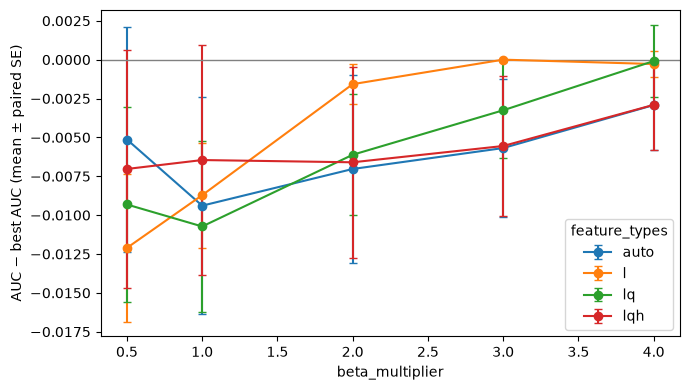

In [5]:
def repeated_block_splits(x_df, y, coords, block_sizes=(800, 900, 1000, 1100, 1200), n_splits=5):
    """5-fold spatial block CV repeated on several block grids: (train, validation) splits."""
    splits = []
    for blk_size in block_sizes:
        blk_cv = SpatialBlockKFold(n_splits=n_splits, block_size=float(blk_size), stratify=True, rnd_seed=42)
        splits += list(blk_cv.split(x_df, y, coords=coords))
    return splits


def boyce_scorer(estimator, x_df, y):
    """Boyce index of a fold's validation samples (a GridSearchCV scorer)."""
    probs = estimator.predict_proba(x_df)[:, 1]
    y = numpy.asarray(y)
    return species_distribution.calc_boyce_index(probs[y == 1], probs[y == 0])["boyce"]


# Score every fold by AUC and by the Boyce index; refit the highest mean AUC.
cv_scoring = {"auc": "roc_auc", "boyce": boyce_scorer}


def paired_one_se_table(search_obj, param_names):
    """
    Spatial CV AUC of each setting of a fitted GridSearchCV, with the mean
    difference from the best setting over the same folds and its standard
    error (paired SE); ``within_1se`` marks the settings not worse than the
    best by more than one paired SE. ``boyce_mean`` is the mean out-of-fold
    Boyce index (folds where it cannot be calculated are left out).
    """
    res = pandas.DataFrame(search_obj.cv_results_)
    n_folds = search_obj.n_splits_
    fold_auc = res[[f"split{k}_test_auc" for k in range(n_folds)]].to_numpy()
    fold_boyce = res[[f"split{k}_test_boyce" for k in range(n_folds)]].to_numpy()
    diff = fold_auc - fold_auc[int(numpy.argmax(fold_auc.mean(axis=1)))]
    out = pandas.DataFrame({new: res[f"param_{old}"] for old, new in param_names.items()})
    out["auc_mean"] = fold_auc.mean(axis=1)
    out["auc_sd"] = fold_auc.std(axis=1, ddof=1)
    out["diff_from_best"] = diff.mean(axis=1)
    out["diff_se"] = diff.std(axis=1, ddof=1) / numpy.sqrt(n_folds)
    out["within_1se"] = out["diff_from_best"] >= -out["diff_se"]
    out["boyce_mean"] = numpy.nanmean(fold_boyce, axis=1)
    return out


train_xy = numpy.column_stack([train_gdf.geometry.x, train_gdf.geometry.y])
# One 5-fold split with 1 km blocks (for the ensemble, section 4), and the
# same CV on five block grids for tuning, as in notebook 02.
blk_cv = SpatialBlockKFold(n_splits=5, block_size=1000.0, stratify=True, rnd_seed=42)
tune_splits = repeated_block_splits(train_gdf[analysis_vars], train_gdf["clsid"], train_xy)

mx_search = GridSearchCV(
    species_distribution.MaxentClassifier(),
    param_grid={
        "beta_multiplier": [0.5, 1.0, 2.0, 3.0, 4.0],
        "feature_types": ["l", "lq", "lqh", "auto"],
    },
    cv=tune_splits,
    scoring=cv_scoring,
    refit="auc",
)
mx_search.fit(train_gdf[analysis_vars], train_gdf["clsid"])
tune_df = paired_one_se_table(
    mx_search, {"beta_multiplier": "beta_multiplier", "feature_types": "feature_types"}
)

# The complexity of each setting: the number of non-zero coefficients of the
# model fitted to all the training samples (tune_maxent_beta also returns
# each setting's AICc, used in the next section).
aicc_df, best_aicc_params = species_distribution.tune_maxent_beta(
    train_gdf,
    None,
    analysis_vars,
    beta_multipliers=(0.5, 1.0, 2.0, 3.0, 4.0),
    feature_types=("l", "lq", "lqh", "auto"),
    metric="aicc",
    use_pbar=False,
)
tune_df = tune_df.merge(
    aicc_df[["beta_multiplier", "feature_types", "n_coefs"]], on=["beta_multiplier", "feature_types"]
)
best_auc_params = tune_df.loc[tune_df["auc_mean"].idxmax(), ["beta_multiplier", "feature_types"]].to_dict()
print("Highest spatial CV AUC:", best_auc_params)

fig, ax = plt.subplots(figsize=(7, 4))
for feat_type, feat_df in tune_df.groupby("feature_types"):
    ax.errorbar(feat_df["beta_multiplier"], feat_df["diff_from_best"], yerr=feat_df["diff_se"],
                marker="o", capsize=3, label=feat_type)
ax.axhline(0, color="grey", lw=1)
ax.set_xlabel("beta_multiplier")
ax.set_ylabel("AUC − best AUC (mean ± paired SE)")
ax.legend(title="feature_types")
fig.tight_layout()
tune_df.round(4)

All the settings score between 0.92 and 0.94. The highest mean AUC is for the **simplest** models: linear features with strong regularisation (`"l"`, `beta_multiplier` 3: 0.935, with 4 non-zero coefficients), with `beta_multiplier` 4 (`"l"` and `"lq"`) just behind. But the flexible models with the weakest regularisation (`"lqh"` and `"auto"` at `beta_multiplier` 0.5, and `"lqh"` at 1) are also within one paired SE of the best: their differences from the best (−0.005 to −0.007) are smaller than their paired SEs (0.007–0.008), because their fold scores vary more. With 23 presences, the cross-validated AUC cannot tell a 4-coefficient linear model from a 20-coefficient hinge model.

Why do `"auto"` and `"lqh"` differ, when `"auto"` means `"lqh"` for 23 presences? In cross-validation, `"auto"` applies the `maxnet` rule to the presences **of each fold's training data**: a fold holding out 9 presences is trained on 14, below the 15 needed for hinges, and gets only `"lq"`. A small illustration of how the defaults depend on sample size.

**AICc** (Akaike's information criterion corrected for small samples; Warren & Seifert 2011) is an alternative that needs no cross-validation: it balances the fit of a model to all the training presences against its number of non-zero coefficients. Lower is better.

In [6]:
# AICc of the models fitted to all the training samples (section 2.2).
aicc_df = aicc_df[aicc_df["feature_types"] != "auto"]  # "auto" is "lqh" here
print("Lowest AICc:", aicc_df.loc[aicc_df["aicc"].idxmin(), ["beta_multiplier", "feature_types"]].to_dict())
aicc_df.sort_values("aicc").head(6).round(1)

Lowest AICc: {'beta_multiplier': 2.0, 'feature_types': 'lqh'}


,beta_multiplier,feature_types,aicc,n_coefs
12,2.0,lqh,328.0,10
13,3.0,lqh,328.2,8
14,4.0,lqh,329.1,6
8,3.0,lq,329.4,5
9,4.0,lq,330.4,4
7,2.0,lq,331.6,7


AICc also prefers linear + quadratic + hinge features with moderate to strong regularisation: `beta_multiplier` 2 (AICc 328.0, 10 coefficients), 3 (328.2, 8) and 4 (329.1, 6) are within about one unit of each other, and differences of less than about 2 are not meaningful. So AICc points to the middle of the range: hinge features, but strongly regularised (6–10 coefficients), where the cross-validation could not separate the 3–4 coefficient linear models from the 20-coefficient hinge models.

**The choice.** As in notebook 02: among the settings whose spatial CV AUC is within one paired standard error of the best, we choose the one with the highest mean out-of-fold Boyce index (ties are unlikely).

In [7]:
best_row = tune_df.loc[tune_df["auc_mean"].idxmax()]
ok_df = tune_df[tune_df["within_1se"]]
sel_row = ok_df.loc[ok_df["boyce_mean"].idxmax()]
mx_params = {
    "beta_multiplier": float(sel_row["beta_multiplier"]),
    "feature_types": str(sel_row["feature_types"]),
}
rsgispy.tools.jsonio.write_dict_to_json(mx_params, os.path.join(out_dir, "maxent_params.json"))
print(f"Best AUC {best_row['auc_mean']:.3f}; selected {mx_params}: AUC {sel_row['auc_mean']:.3f} "
      f"({sel_row['diff_from_best']:+.4f}, paired SE {sel_row['diff_se']:.4f}), "
      f"{int(sel_row['n_coefs'])} coefficients, out-of-fold Boyce {sel_row['boyce_mean']:.3f}")

Best AUC 0.935; selected {'beta_multiplier': 0.5, 'feature_types': 'auto'}: AUC 0.930 (-0.0051, paired SE 0.0072), 20 coefficients, out-of-fold Boyce 0.480


## 3. Fit the Model and Inspect Its Features

`fit_sklearn_mdl` fits the model (`return_model=True` returns it). `selected_features_` lists the features with non-zero coefficients: the whole model is the sum of these features × their coefficients (on the scale of the link, η). Feature names give the variable and, for hinges, the knot in the variable's units: `hinge_fwd(x, k)` is 0 below `k` and rises above it; `hinge_rev(x, k)` is 0 above `k` and rises below it. A negative coefficient on `hinge_fwd(ledges_dist, 500)`, for example, would mean "suitability falls once you are more than 500 m from a ledge".

In [8]:
mx_mdl, train_acc, test_acc, test_auc = species_distribution.fit_sklearn_mdl(
    est_cls_obj=species_distribution.MaxentClassifier(**mx_params),
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    test_vec_file=test_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    cls_col="clsid",
    return_model=True,
)
mx_mdl.selected_features_.round(3)

Classifier Train Score = 98.13%
Classifier Test Score = 97.87%


,feature,feature_class,coef
0,calc_grass_dist^2,q,-15.693
1,ledges_dist^2,q,-73.851
2,winter_temp^2,q,-16.965
3,"hinge_rev(calc_grass_dist,1619.1)",h,-1.878
4,"hinge_fwd(flush_dist,1220.23)",h,-6.113
5,"hinge_rev(flush_dist,497.132)",h,-1.184
6,"hinge_rev(flush_dist,1220.23)",h,-3.202
7,"hinge_fwd(impr_grass_dist,1755.38)",h,-1.063
8,"hinge_rev(ledges_dist,109.019)",h,0.594
9,"hinge_fwd(rock_dist,2682.33)",h,-2.857


The rule selects `"auto"` (here `"lqh"`) with the weakest regularisation, `beta_multiplier` 0.5 (AUC 0.930, within one paired SE of the best; out-of-fold Boyce 0.48, against 0.25–0.42 for the other accepted settings). This is the **most complex** model of the grid: **20 features**, including

* quadratic terms for the distances to ledges (−73.9) and to calcareous grassland (−15.7), and for winter temperature (−17.0);
* three hinges on winter temperature, below 2.70, 2.94 and 2.98 °C;
* three hinges on the distance to flushes, five on the distance to rock and three on the distance to scree, with coefficients of both signs.

Every variable is now in the model; improved grassland and calcareous grassland, which the L1 penalty removed at stronger regularisation, have features too. The coefficients apply to the min-max scaled variables, so their sizes are not comparable with those of notebook 02.

Remember why this model was chosen: it ranks presences against background no worse than the simple models (AUC), and it ranked the presences *within* the suitable area better in the held-out folds (Boyce index). But the out-of-fold Boyce indices come from folds of 3–9 presences, and the differences between the accepted settings are well within their noise. The response curves (section 5.1) show what such a flexible model does with 23 presences; compare it with the AICc choice (`"lqh"`, `beta_multiplier` 2, 10 coefficients) or the simplest accepted model (`"l"`, `beta_multiplier` 4, 3 coefficients) if you want to see the alternatives: change `mx_params` and re-run the notebook.

## 4. Evaluate the Model

The same measures as notebook 02, on the same test points: AUC, TSS at the threshold maximising it, sensitivity and specificity, and the Boyce index; a null-model test of the AUC; and an ensemble fitted with the same spatial folds.

auc                     0.987
threshold               0.172
tss                     0.940
sensitivity             1.000
specificity             0.940
omission_rate           0.000
commission_rate         0.060
kappa                   0.103
accuracy                0.941
balanced_accuracy       0.970
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.768
null_p95                0.654
null_p_value            0.010
dtype: float64

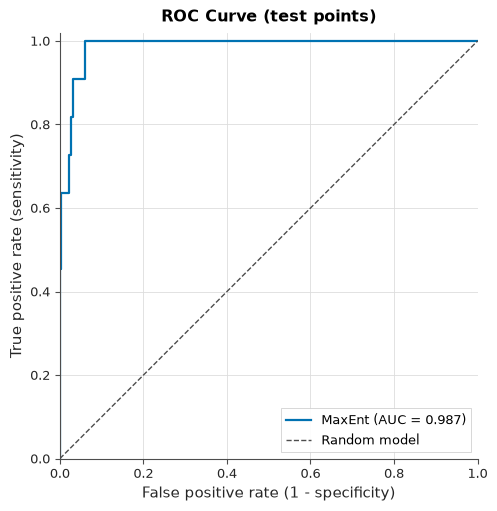

In [9]:
test_probs = species_distribution.get_positive_class_probs(mx_mdl, test_gdf[analysis_vars])
mx_metrics = species_distribution.calc_sdm_eval_metrics(test_y, test_probs, bg_scores="absences")
fpr, tpr, auc = species_distribution.calc_binary_roc_auc(test_y, test_probs)
fig, ax = species_distribution.plot_roc_curve(
    fpr, tpr, auc, label="MaxEnt", title="ROC Curve (test points)",
    out_plot_file=os.path.join(plots_dir, "maxent_testing_roc_curve.png"),
)
null_res = species_distribution.calc_null_model_auc(
    species_distribution.MaxentClassifier(**mx_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    n_pres=n_train_pres, n_reps=99, observed_auc=mx_metrics["auc"], rnd_seed=42,
    plot_file=os.path.join(plots_dir, "maxent_null_model_auc.png"), use_pbar=False,
)
mx_metrics["null_p95"] = null_res["null_p95"]
mx_metrics["null_p_value"] = null_res["p_value"]
pandas.Series(mx_metrics).round(3)

On the test points MaxEnt has an AUC of 0.987 and a TSS of 0.940 (all 11 presences predicted present, 94 % of the pseudo-absences predicted absent at the threshold 0.172), and a Boyce index of 0.768. The null models reach a 95th percentile AUC of 0.654, far below the observed AUC (p = 0.01). The AUC and TSS are higher than those of the logistic regression (AUC 0.962, TSS 0.875), and the Boyce index lower (0.90 for the logistic regression), but with 11 test presences, differences of about 0.01–0.02 in AUC are within the noise; notebook 05 compares the models in detail.

In [10]:
mx_mdls, mx_scores_df = species_distribution.fit_kfold_sklearn_mdls(
    species_distribution.MaxentClassifier(**mx_params),
    train_gdf, None, test_gdf, None, analysis_vars,
    cv=blk_cv, rnd_seed=42, return_scores=True, use_pbar=False,
)
score_cols = ["val_auc", "val_tss", "val_boyce", "test_auc", "test_tss"]
print(mx_scores_df[["fold", "n_train", "n_val"] + score_cols].round(3))

ens_test_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, test_gdf[analysis_vars]) for mdl in mx_mdls],
    axis=0,
)
mx_ens_metrics = species_distribution.calc_sdm_eval_metrics(test_y, ens_test_probs, bg_scores="absences")
pandas.Series(mx_ens_metrics).round(3)

ROC: 0.9546969696969697 - 0.9840909090909089 - 0.9888181818181818
Train: 0.9097222222222222 - 0.9846920612317551 - 0.9871931696905016
Test: 0.9146462969113252 - 0.9810694121554301 - 0.9833942211889738
Validation (out-of-fold) ROC: 0.85465808911127 - 0.9567284831193533 - 0.9736467236467237
   fold  n_train   n_val  val_auc  val_tss  val_boyce  test_auc  test_tss
0     0   5616.0  1407.0    0.960    0.923      0.491     0.955     0.887
1     1   5615.0  1408.0    0.974    0.940      0.645     0.984     0.909
2     2   5618.0  1405.0    0.957    0.934      0.757     0.986     0.938
3     3   5622.0  1401.0    0.921    0.838      0.516     0.984     0.950
4     4   5621.0  1402.0    0.855    0.714      0.602     0.989     0.956


auc                     0.987
threshold               0.174
tss                     0.939
sensitivity             1.000
specificity             0.939
omission_rate           0.000
commission_rate         0.061
kappa                   0.102
accuracy                0.940
balanced_accuracy       0.970
prevalence              0.004
n_presence             11.000
n_absence            3000.000
boyce                   0.773
dtype: float64

The five spatial members have out-of-fold AUCs from 0.855 to 0.974 (mean 0.933) and TSS from 0.71 to 0.94 (mean 0.87), very close to the logistic regression (0.932 and 0.87). The out-of-fold Boyce index is more stable than the logistic regression's (0.49 to 0.76, mean 0.60), but still estimated from only 3–9 presences per fold. The median of the five members has a test AUC of 0.987, TSS 0.939 and Boyce index 0.773.

In [11]:
resid_df = species_distribution.calc_residual_autocorrelation(
    mx_mdl, train_gdf, None, analysis_vars,
    dist_classes=[0, 250, 500, 1000, 1500, 2000, 3000, 4000, 6000],
    n_perms=99, rnd_seed=42,
)
resid_df[["dist_lower", "dist_upper", "morans_i", "p_value"]].round(3)

,dist_lower,dist_upper,morans_i,p_value
0,0.0,250.0,0.678,0.01
1,250.0,500.0,0.546,0.01
2,500.0,1000.0,0.350,0.01
3,1000.0,1500.0,0.226,0.01
4,1500.0,2000.0,0.159,0.01
5,2000.0,3000.0,0.070,0.01
6,3000.0,4000.0,-0.018,0.01
7,4000.0,6000.0,-0.044,0.01


The residuals are autocorrelated, but less than those of the logistic regression (Moran's I 0.68 below 250 m, against 0.92; about 0 at 3–4 km): with 20 features, MaxEnt follows the local pattern of the presences more closely, which removes part of the spatial structure of the residuals. Part, not all: the same caution about the independence of the samples applies to its test scores, and fitting the presences closely is also what over-fitting looks like (section 5.1).

## 5. Interpreting the MaxEnt Model

### 5.1 Response Curves

The same function as in notebook 02, here with raw values (`normalised_data=False`). Two things specific to MaxEnt: the y axis is the **cloglog** output, and with `clamp=True` (the default) a variable beyond its training range is treated as if it were at the end of the range, so the curves (and the map) stay flat beyond the training data instead of extrapolating.

calc_grass_dist Range:	(0.0 - 6102.75341796875): Mean = 1280.7439933445144
Calculating Response Curve for 'calc_grass_dist'
flush_dist Range:	(0.0 - 2214.497802734375): Mean = 929.4367184846298
Calculating Response Curve for 'flush_dist'
impr_grass_dist Range:	(0.0 - 3739.732666015625): Mean = 1950.0651271654212
Calculating Response Curve for 'impr_grass_dist'
ledges_dist Range:	(0.0 - 5341.947265625): Mean = 355.9866565206776
Calculating Response Curve for 'ledges_dist'
rock_dist Range:	(0.0 - 6917.6005859375): Mean = 2436.267542300017
Calculating Response Curve for 'rock_dist'
scree_dist Range:	(0.0 - 3493.13623046875): Mean = 493.25894231381625
Calculating Response Curve for 'scree_dist'
winter_temp Range:	(2.5071563720703125 - 4.4408345222473145): Mean = 2.8537858465443486
Calculating Response Curve for 'winter_temp'


,variable,min suitability,max suitability,at value,>= half max from,to
0,calc_grass_dist,0.00,0.99,1380.02,0.00,2606.70
1,flush_dist,0.02,1.00,1212.97,367.23,1635.84
2,impr_grass_dist,0.80,0.99,0.00,0.00,3739.73
3,ledges_dist,0.00,1.00,0.00,0.00,885.85
4,rock_dist,0.25,1.00,0.00,0.00,5631.41
5,scree_dist,0.46,1.00,579.26,0.00,3493.14
6,winter_temp,0.00,0.99,2.72,2.67,3.26


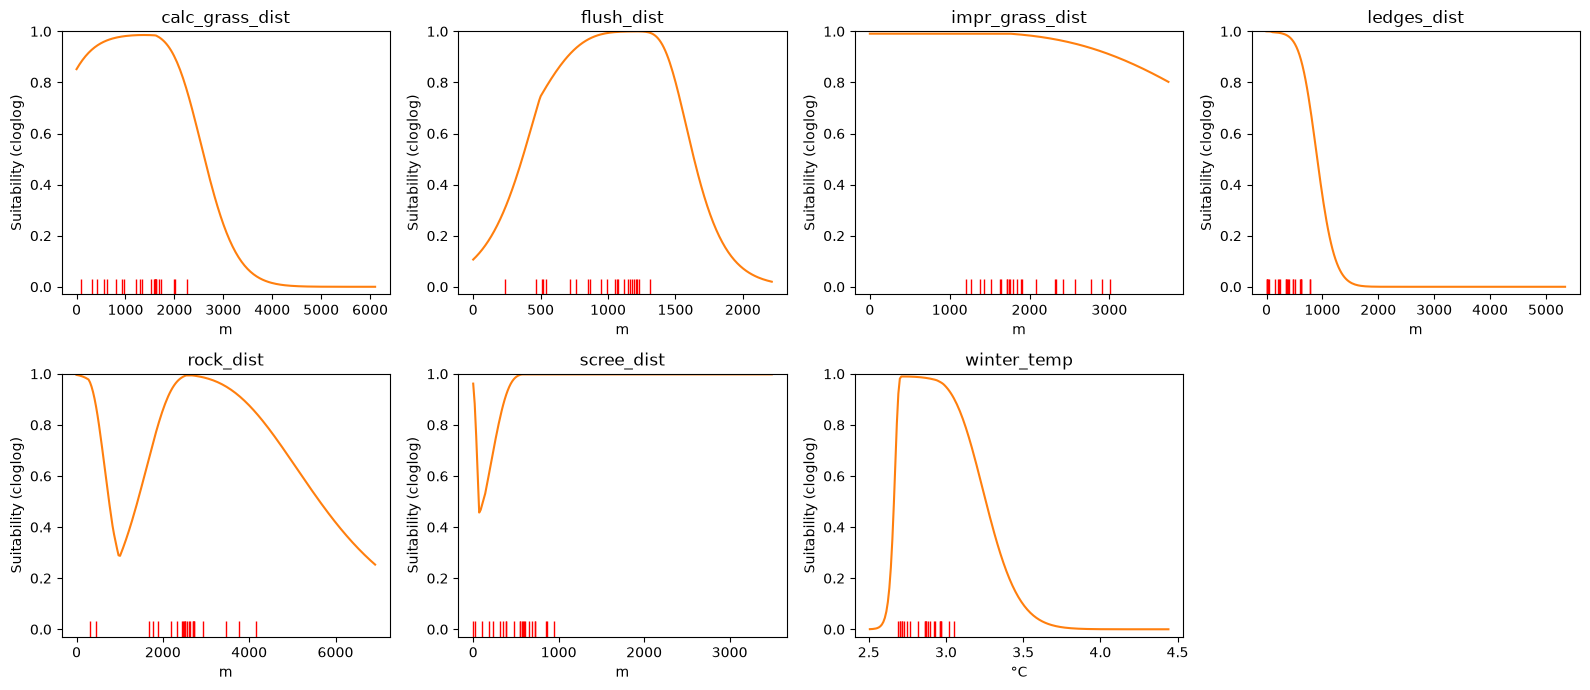

In [12]:
mx_resp_df = species_distribution.sklearn_mdl_variable_response_curves(
    est_cls_obj=mx_mdl,
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    analysis_vars=analysis_vars,
    output_file=os.path.join(out_dir, "maxent_response_curves.csv"),
    response_plots_dir=None,
    n_samples=200,
    cls_col="clsid",
)
train_pres_gdf = train_gdf[train_gdf["clsid"] == 1]
units = {"winter_temp": "°C"}
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, var_name in zip(axs.flatten(), analysis_vars):
    ax.plot(mx_resp_df[f"{var_name}_vals"], mx_resp_df[f"{var_name}_resp"], color="tab:orange")
    ax.plot(train_pres_gdf[var_name], numpy.zeros(len(train_pres_gdf)), "|", color="red", ms=12)
    ax.set_ylim(-0.03, 1.0)
    ax.set_title(var_name)
    ax.set_xlabel(units.get(var_name, "m"))
    ax.set_ylabel("Suitability (cloglog)")
axs.flatten()[-1].axis("off")
fig.tight_layout()

half_rows = []
for var_name in analysis_vars:
    vals = mx_resp_df[f"{var_name}_vals"].to_numpy()
    resp = mx_resp_df[f"{var_name}_resp"].to_numpy()
    above = vals[resp >= resp.max() / 2]
    half_rows.append({"variable": var_name, "min suitability": resp.min(), "max suitability": resp.max(),
                      "at value": vals[resp.argmax()], ">= half max from": above.min(), "to": above.max()})
pandas.DataFrame(half_rows).round(2)

The responses of this 20-feature model are far more complex than those of the logistic regression, and several of them show the signs of **over-fitting**: shapes that follow the gaps between 23 presences rather than an ecological response.

* **Distance to ledges** — suitability is close to its maximum up to about 500 m from a ledge, above half its maximum within about 890 m and close to 0 beyond about 1.5 km: a sharper version of the logistic regression's response (half maximum at about 1050 m). The most robust response of the model.
* **Winter temperature** — a narrow plateau from 2.7 to about 3.1 °C (above half its maximum between 2.67 and 3.26 °C), with a near-vertical drop **below 2.7 °C**: the coldest training presence is at 2.69 °C, and the hinges at 2.70–2.98 °C make everything colder than the presences unsuitable. The logistic regression's parabola instead declined only gently towards the coldest ground (0.69 at 2.5 °C). Neither model has data on the cold side, so this difference is a difference of assumptions, not of evidence.
* **Distance to flushes** — low at a flush (0.1), rising to 1 between about 800 and 1300 m and then *falling* again to near 0 at 2 km. The rise is the dry-ground effect of the logistic regression; the fall beyond 1.6 km has no obvious ecological meaning: no training presence is more than about 1.3 km from a flush, so the model has simply learnt that the presences are not there.
* **Distance to rock** — high at a rock exposure, a deep dip at about 1 km, high again at 2–3 km (where most presences are) and falling beyond: a response drawn around the presences, not a plausible ecological relationship.
* **Distance to scree** — a sharp dip within about 100 m of scree; **calcareous grassland** — suitability falls from 1 to 0 between about 2 and 4 km from calcareous grassland, i.e. beyond the most distant presence; **improved grassland** — a slight decline far from improved grassland.

So the model ranks the test points very well, but several of its responses are not interpretable, and they would behave unpredictably in other places or conditions. This is the risk of choosing the most flexible setting that the cross-validation cannot distinguish from the simpler ones; the Boyce tie-break is no protection against it when its own differences are within the noise. The suitability values are cloglog outputs; clamping keeps every curve flat beyond the training range.

### 5.2 Jackknife Variable Importance

In [13]:
mx_jk_df = species_distribution.sklearn_jackknife_var_importance(
    est_cls_obj=species_distribution.MaxentClassifier(**mx_params),
    train_vec_file=train_gdf,
    train_vec_lyr=None,
    test_vec_file=test_gdf,
    test_vec_lyr=None,
    analysis_vars=analysis_vars,
    out_var_importance_file=os.path.join(out_dir, "maxent_jackknife_var_importance.csv"),
    out_importance_auc_plot=os.path.join(plots_dir, "maxent_jackknife_auc.png"),
    cls_col="clsid",
    use_pbar=False,
)
print(f"Test AUC with all the variables: {mx_metrics['auc']:.3f}")
mx_jk_df[["roc_test_acc_leave_var_out", "roc_test_acc_only_var"]].round(3)

Test AUC with all the variables: 0.987


,roc_test_acc_leave_var_out,roc_test_acc_only_var
calc_grass_dist,0.985,0.833
flush_dist,0.976,0.919
impr_grass_dist,0.986,0.789
ledges_dist,0.974,0.899
rock_dist,0.986,0.845
scree_dist,0.984,0.779
winter_temp,0.986,0.865


On their own, the distances to flushes (AUC 0.919) and ledges (0.899), and winter temperature (0.865), are again the most informative. Every variable does better alone than in the logistic regression (e.g. rock 0.845 against 0.655, calcareous grassland 0.833 against 0.470): with hinge features, MaxEnt can fit a non-monotonic response to a single variable, which one linear term cannot. Part of this is real (most presences are 1.7–4 km from mapped rock), part is the flexibility of the model fitting the training presences. Leaving out ledges (0.987 → 0.974) or flushes (0.976) lowers the AUC most; leaving out any other variable changes it by 0.003 or less: they add little that ledges, flushes and temperature do not already provide, although the model uses them.

### 5.3 SHAP

MaxEnt is neither a tree model nor a linear model of its inputs (it is linear in its *features*), so SHAP needs its model-agnostic `KernelExplainer` on `predict_proba`: the SHAP values are on the **probability (cloglog) scale**, unlike the log-odds SHAP values of notebook 02. With `use_tree_explainer=None`, `shap_sklearn_mdl_explainer` chooses the explainer itself: it uses `LinearExplainer` only when the model's output is linear in the input variables (which it checks numerically), so for MaxEnt, whose coefficients apply to the derived features, it falls back to `KernelExplainer`. Kernel SHAP is slow (it evaluates the model on many perturbed copies of every sample, against a background sample), so we explain a small table: all 23 training presences and 177 randomly chosen background points. The same table is the explainer's background, so the reference ("average") prediction is that of this sample, in which presences are over-represented.

Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/200 [00:00<?, ?it/s]

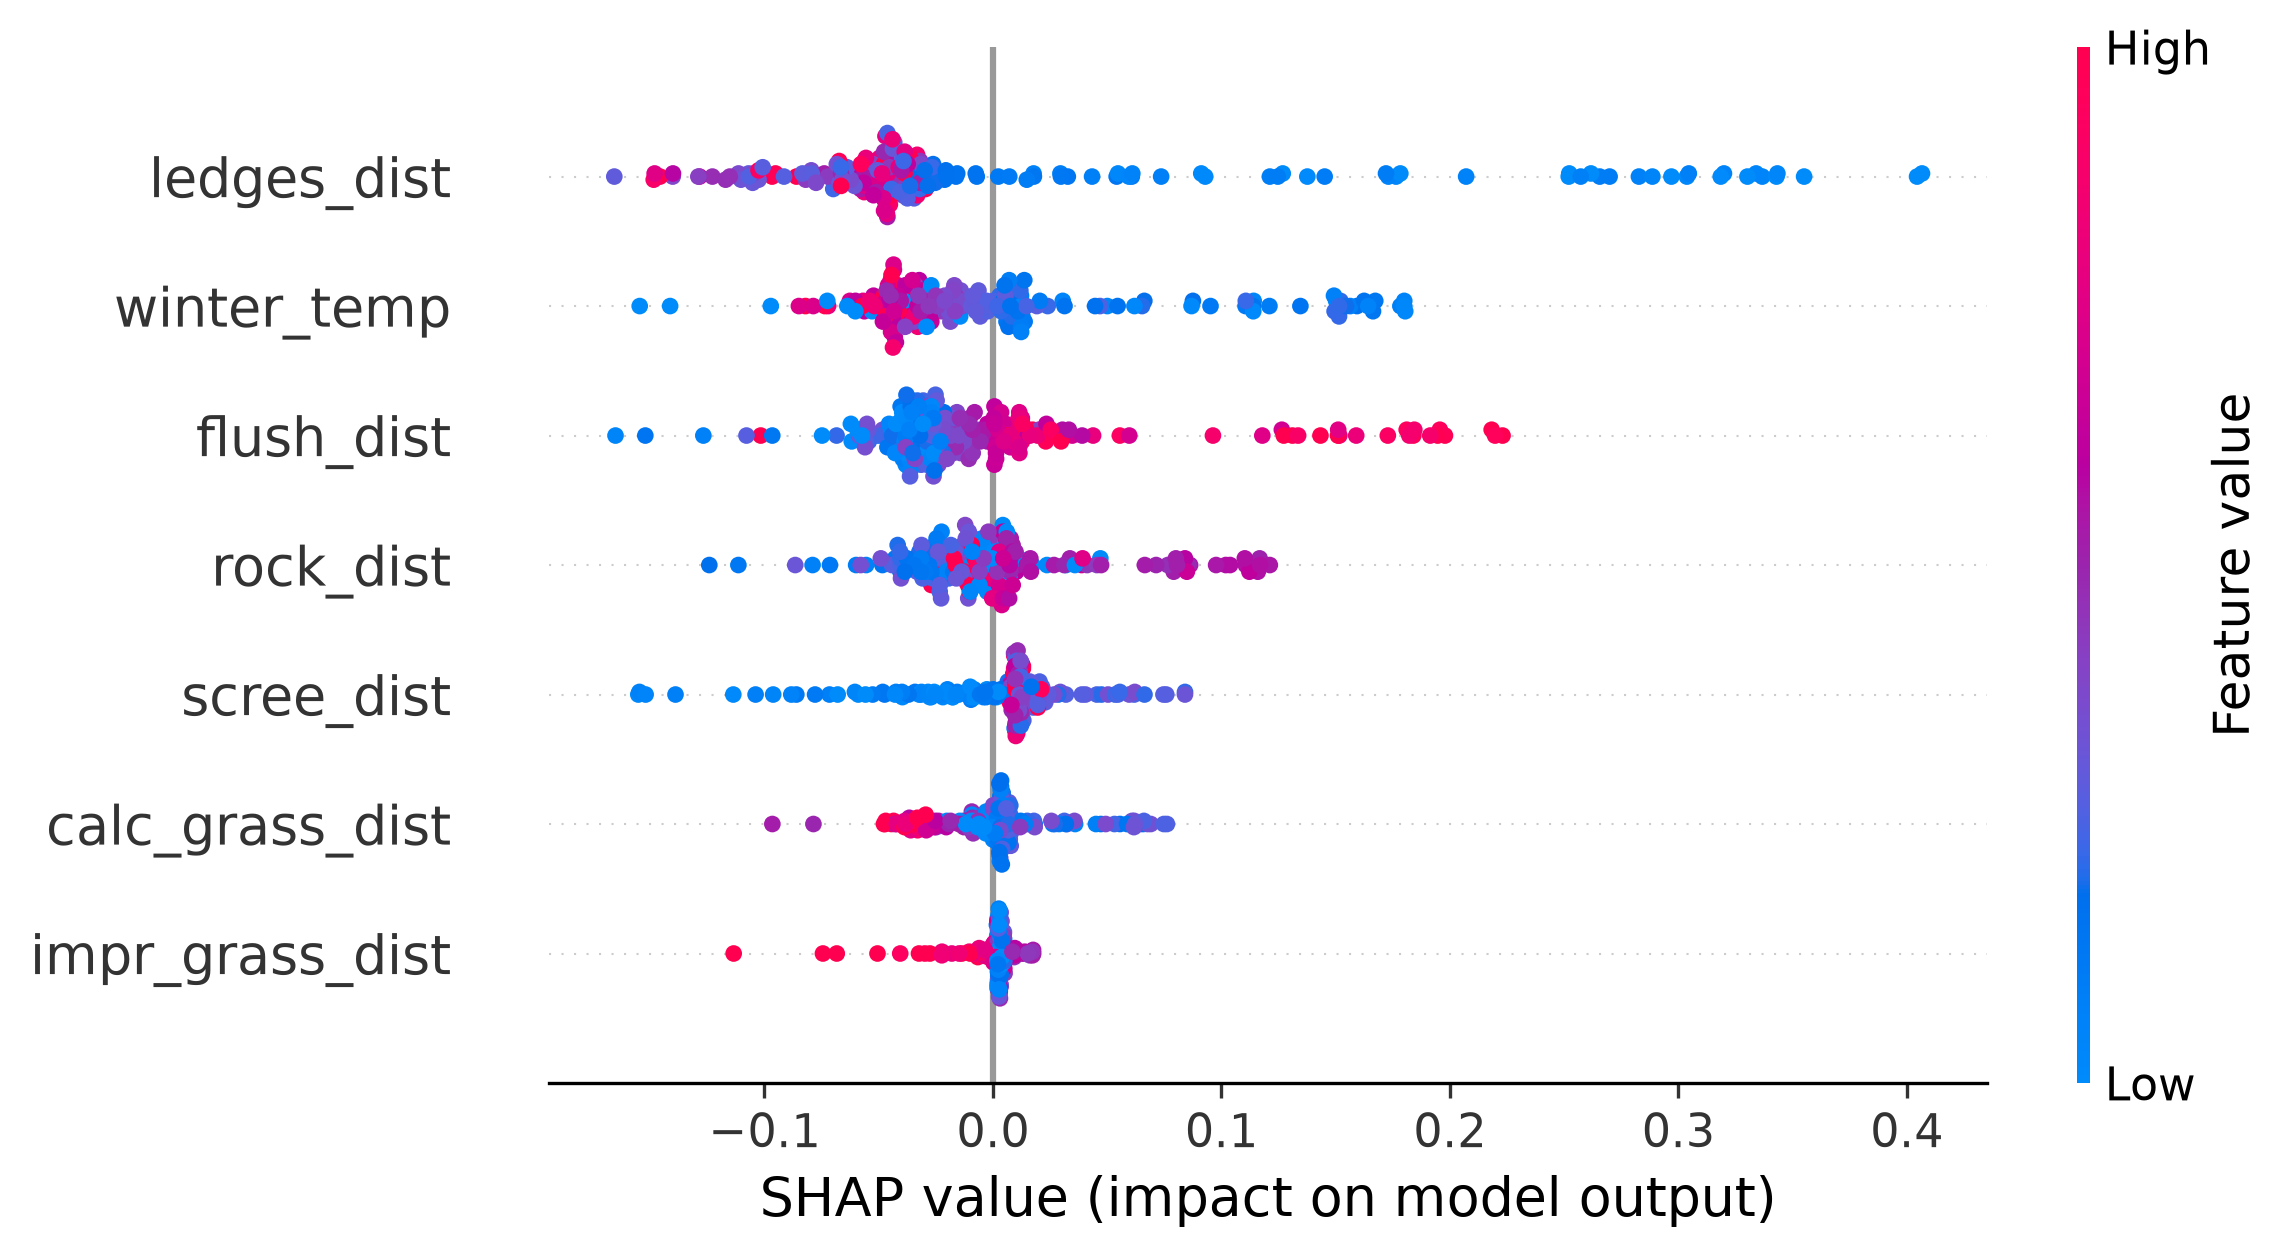

Using 200 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


ledges_dist        0.0883
winter_temp        0.0481
flush_dist         0.0456
rock_dist          0.0276
scree_dist         0.0250
calc_grass_dist    0.0183
impr_grass_dist    0.0068
Name: mean |SHAP| (cloglog), dtype: float64

In [14]:
shap_gdf = pandas.concat(
    [
        train_gdf[train_gdf["clsid"] == 1],
        train_gdf[train_gdf["clsid"] == 0].sample(n=177, random_state=42),
    ]
)
if importlib.util.find_spec("shap") is not None:
    species_distribution.shap_sklearn_mdl_explainer(
        est_cls_obj=mx_mdl,
        train_vec_file=shap_gdf,
        train_vec_lyr=None,
        analysis_vars=analysis_vars,
        shap_summary_plot=os.path.join(plots_dir, "maxent_shap_summary.png"),
        use_tree_explainer=None,  # rsgispy chooses: KernelExplainer for MaxEnt
    )
    display(Image(filename=os.path.join(plots_dir, "maxent_shap_summary.png"), width=650))

    # The mean |SHAP| of each variable, for the comparison in notebook 05.
    import shap

    shap_x = shap_gdf[analysis_vars]
    kernel_exp = shap.KernelExplainer(lambda x: mx_mdl.predict_proba(
        pandas.DataFrame(x, columns=analysis_vars))[:, 1], shap_x)
    mx_shap_vals = kernel_exp.shap_values(shap_x, silent=True)
    mx_shap_df = pandas.Series(numpy.abs(mx_shap_vals).mean(axis=0), index=analysis_vars,
                               name="mean |SHAP| (cloglog)")
    display(mx_shap_df.sort_values(ascending=False).round(4))
else:
    print("The shap package is not installed, so the SHAP analysis is skipped.")

The SHAP values (on the cloglog scale) rank the distance to ledges first (mean |SHAP| 0.09), then winter temperature and flushes (0.05 each), rock and scree (0.03), calcareous grassland (0.02) and improved grassland (0.01): unlike the simpler models, every variable contributes. The summary plot shows the directions: being close to a ledge (blue) raises the prediction by up to about 0.4 for this sample, warm temperatures (red) lower it, and being far from flushes (red) raises it. The low temperatures (blue) appear on both sides: the coldest ground is pushed down by the steep cold-side drop of section 5.1. Since this model has no product features, the spread of SHAP values at a given value of a variable comes from the non-linear cloglog output, not from learnt interactions.

### 5.4 Sobol Sensitivity Analysis

On the probability (cloglog) scale, as in notebook 02. As there, interactions (ST > S1) can come from two sources: the non-linear output link (as for the logistic regression), and product features, if any were selected (here none: products need 80 presences in the default rule, and `"lqh"` has none).

In [15]:
if importlib.util.find_spec("SALib") is not None:
    mx_total_si, mx_first_si, mx_second_si = species_distribution.salib_sklearn_mdl_sensitivity(
        est_cls_obj=mx_mdl,
        train_vec_file=train_gdf,
        train_vec_lyr=None,
        analysis_vars=analysis_vars,
        n_samples=1024,
        sobol_overall_file=os.path.join(out_dir, "maxent_sobol_total.csv"),
        sobol_first_file=os.path.join(out_dir, "maxent_sobol_first_order.csv"),
        sobol_second_file=os.path.join(out_dir, "maxent_sobol_second_order.csv"),
        rnd_seed=42,
    )
    order = mx_total_si["ST"].sort_values(ascending=False).index
    display(pandas.concat([mx_total_si, mx_first_si], axis=1).loc[order].round(3))
    print("Largest second order (pairwise interaction) indices:")
    display(mx_second_si.sort_values("S2", ascending=False).head(5).round(3))
else:
    print("The SALib package is not installed, so the Sobol analysis is skipped.")

calc_grass_dist Range:	(0.0 - 6102.75341796875)
flush_dist Range:	(0.0 - 2214.497802734375)
impr_grass_dist Range:	(0.0 - 3739.732666015625)
ledges_dist Range:	(0.0 - 5341.947265625)
rock_dist Range:	(0.0 - 6917.6005859375)
scree_dist Range:	(0.0 - 3493.13623046875)
winter_temp Range:	(2.5071563720703125 - 4.4408345222473145)


,ST,ST_conf,S1,S1_conf
variable,,,,
ledges_dist,1.284,1.067,0.017,0.024
flush_dist,0.502,0.585,0.022,0.042
calc_grass_dist,0.487,0.401,0.001,0.007
winter_temp,0.433,0.409,-0.007,0.021
rock_dist,0.179,0.127,0.022,0.042
scree_dist,0.135,0.196,-0.010,0.019
impr_grass_dist,0.020,0.026,-0.001,0.002


Largest second order (pairwise interaction) indices:


S2  S2_conf
variable_1      variable_2                 
calc_grass_dist ledges_dist  0.200    0.436
flush_dist      ledges_dist  0.084    0.308
ledges_dist     winter_temp  0.038    0.048
                scree_dist   0.017    0.040
scree_dist      winter_temp  0.015    0.034

The distance to ledges has the largest total index, followed by flushes, calcareous grassland and temperature, but these indices are **not reliable** here: the total index of ledges is above 1 (1.28), which is impossible for a true index, and the confidence intervals (±0.4 to ±1.1) are as large as the indices themselves. The first order indices are all close to 0 (≤ 0.02), and the second order indices have intervals that include 0.

This is a property of the model, not of SALib. With its steep hinges and sharp cut-offs (section 5.1), the predicted suitability is close to 0 almost everywhere in the variable space and high only in a small region where all the variables are favourable at once; uniform Sobol samples rarely hit that region, and the estimates are dominated by a few samples. The same `n_samples=1024` gave tight intervals for the smooth logistic regression (notebook 02). For a model like this, increase `n_samples` (e.g. to 8192) before reading the indices, and treat the S1 ≈ 0 and large ST as "the variables only matter together", which for this model is true by construction.

## 6. Predict the MaxEnt Suitability Map

The median cloglog output of the five-member spatial ensemble, with the standard deviation and interquartile range of the members, thresholded at the maximum-TSS threshold of the ensemble's test predictions (and the 10th percentile training presence threshold for comparison). No `normalise_data`: MaxEnt was trained on raw values.

In [16]:
mx_prob_img = os.path.join(out_dir, "Snowdon_Beetle_maxent_sdm_prob.tif")
species_distribution.pred_ensemble_sklearn_mdls_prob(
    mx_mdls, valid_msk_img, 1, env_vars, analysis_vars, mx_prob_img,
    gdalformat="GTIFF", calc_stats=True, uncertainty=["std", "iqr"], use_pbar=False,
)
ens_train_probs = numpy.median(
    [species_distribution.get_positive_class_probs(mdl, train_gdf[analysis_vars]) for mdl in mx_mdls],
    axis=0,
)
mx_thres = {
    "max TSS": species_distribution.calc_binary_threshold(test_y, ens_test_probs, method="max_tss"),
    "10th percentile training presence": float(
        numpy.percentile(ens_train_probs[train_gdf["clsid"] == 1], 10)
    ),
}
with rasterio.open(mx_prob_img) as src:
    mx_prob_arr = src.read(1)
    pxl_km2 = abs(src.res[0] * src.res[1]) / 1e6
valid = mx_prob_arr >= 0
thres_rows = []
for name, thres in mx_thres.items():
    test_bin = (ens_test_probs >= thres).astype(int)
    thres_rows.append({
        "threshold": name, "value": thres,
        "test sensitivity": test_bin[test_y == 1].mean(),
        "test specificity": 1 - test_bin[test_y == 0].mean(),
        "suitable area (km²)": (mx_prob_arr[valid] >= thres).sum() * pxl_km2,
        "% of study area": 100 * (mx_prob_arr[valid] >= thres).mean(),
    })
display(pandas.DataFrame(thres_rows).round(3))
mx_boyce = species_distribution.calc_boyce_index_from_raster(
    mx_prob_img, presences_vec_file, presences_vec_lyr, use_pbar=False
)
print(f"Boyce index of the map: {mx_boyce['boyce']:.3f}")

mx_bin_img = os.path.join(out_dir, "Snowdon_Beetle_maxent_sdm_bin.tif")
rsgispy.imagecalc.maths.band_maths(
    mx_bin_img,
    f"prob < 0 ? 255 : (prob >= {mx_thres['max TSS']} ? 1 : 0)",
    [rsgispy.imagecalc.maths.BandDefn("prob", mx_prob_img, 1)],
    gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=255, use_pbar=False,
)

,threshold,value,test sensitivity,test specificity,suitable area (km²),% of study area
0,max TSS,0.174,1.000,0.939,10.267,6.033
1,10th percentile training presence,0.278,0.909,0.962,6.803,3.998


Boyce index of the map: 0.811


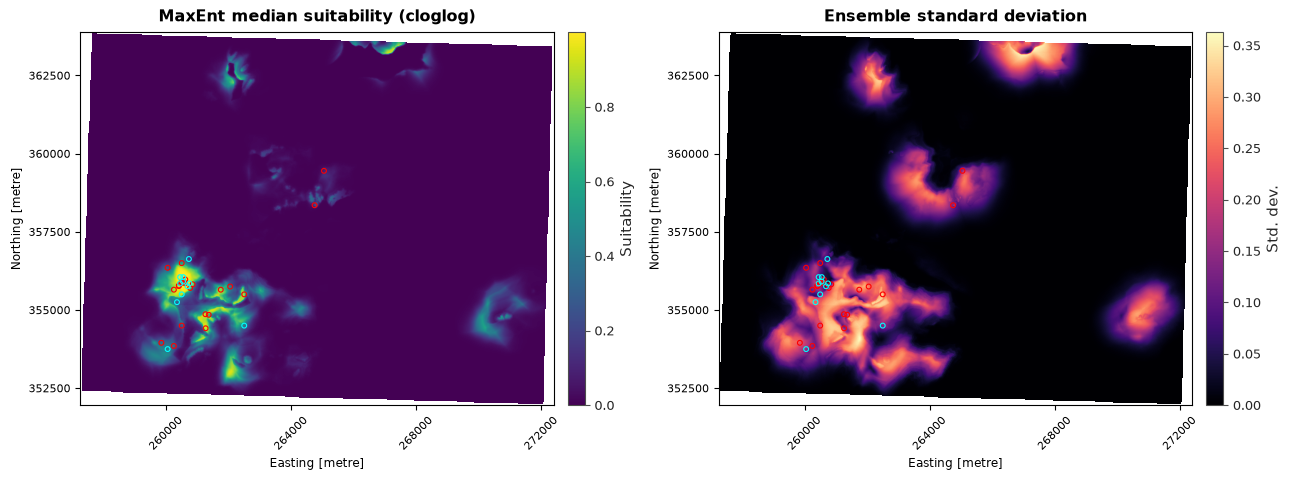

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (band, title, cmap, label) in zip(
    axs, [(1, "MaxEnt median suitability (cloglog)", "viridis", "Suitability"),
          (2, "Ensemble standard deviation", "magma", "Std. dev.")]
):
    rsgispy.mapping.raster.create_raster_cmap_img_map(
        ax, input_img=mx_prob_img, img_band=band, title_str=title, cmap_name=cmap,
        show_colour_bar=True, cbar_label=label, show_scale_bar=False,
    )
    train_pres_gdf.plot(ax=ax, facecolor="none", edgecolor="red", markersize=12, linewidth=0.8)
    test_gdf[test_gdf["clsid"] == 1].plot(ax=ax, facecolor="none", edgecolor="cyan", markersize=12, linewidth=0.8)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()

The MaxEnt map is much more concentrated than the logistic regression's: high suitability is limited to patches around the cluster of records on Yr Wyddfa and a few smaller patches nearby, while the north, the east and the area around the two isolated central records are only weakly suitable. The ensemble members disagree most (highest standard deviation) around the records and over the central, northern and eastern patches: with 20 features, the shape of the suitable area depends on which blocks of presences a member was trained on.

The maximum-TSS threshold (0.174) predicts 10.3 km² (6.0 % of the study area) suitable, with all 11 test presences inside it; the 10th percentile training presence threshold (0.278) gives 6.8 km² (4.0 %) and misses one test presence. The low thresholds reflect the cloglog scale of a model that predicts values near 0 almost everywhere. The Boyce index of the map is 0.811.

## 7. Projecting to a Warmer Climate: Clamping

Notebook 02 projected the logistic regression to winters 0.5 °C and 1 °C warmer (remember that, with the weak altitudinal gradient of this temperature raster, these are large changes; notebook 02, section 16). Here we project the MaxEnt ensemble to the same scenarios, thresholded with its own current maximum-TSS threshold.

MESS depends only on the training samples and the rasters, not on the model, so the areas outside the training range are the same as in notebook 02 (6.6 % of the study area at +0.5 °C, 34 % at +1 °C). What differs is what the model does there: MaxEnt **clamps** each variable to its training range, so a pixel warmer than the warmest training sample is predicted as if it had the warmest training temperature, whereas the logistic regression's parabola keeps falling.

In [18]:
scen_rows = []
for warming in [0.5, 1.0]:
    tag = f"plus{warming:.1f}".replace(".", "_")
    warm_temp_img = os.path.join(lr_dir, f"Mean_Winter_Temp_{tag}.tif")
    warm_env_vars = species_distribution.copy_env_vars_for_scenario(
        env_vars, {"winter_temp": warm_temp_img}
    )
    warm_prob_img = os.path.join(out_dir, f"Snowdon_Beetle_maxent_sdm_prob_{tag}.tif")
    species_distribution.pred_ensemble_sklearn_mdls_prob(
        mx_mdls, valid_msk_img, 1, warm_env_vars, analysis_vars, warm_prob_img,
        calc_stats=True, use_pbar=False,
    )
    warm_bin_img = os.path.join(out_dir, f"Snowdon_Beetle_maxent_sdm_bin_{tag}.tif")
    rsgispy.imagecalc.maths.band_maths(
        warm_bin_img,
        f"prob < 0 ? 255 : (prob >= {mx_thres['max TSS']} ? 1 : 0)",
        [rsgispy.imagecalc.maths.BandDefn("prob", warm_prob_img, 1)],
        gdalformat="GTIFF", datatype=rsgispy.TYPE_8UINT, no_data_val=255, use_pbar=False,
    )
    summary = species_distribution.calc_range_change(
        mx_bin_img, warm_bin_img, os.path.join(out_dir, f"maxent_range_change_{tag}.tif"),
        in_msk_img=valid_msk_img, use_pbar=False,
    )
    scen_rows.append(
        {
            "warming (°C)": warming,
            "current (km²)": summary["current_area"] / 1e6,
            "scenario (km²)": summary["future_area"] / 1e6,
            "lost (km²)": summary["area_lost"] / 1e6,
            "gained (km²)": summary["area_gained"] / 1e6,
            "stable (km²)": summary["area_stable"] / 1e6,
            "net change (%)": summary["pct_net_change"],
        }
    )
scen_df = pandas.DataFrame(scen_rows)
scen_df.round(2)

,warming (°C),current (km²),scenario (km²),lost (km²),gained (km²),stable (km²),net change (%)
0,0.5,10.27,3.73,8.15,1.61,2.12,-63.71
1,1.0,10.27,0.00,10.27,0.00,0.00,-100.00


With +0.5 °C, MaxEnt's suitable area falls from 10.3 km² to 3.7 km² (−64 %): 8.2 km² is lost, 2.1 km² is stable and 1.6 km² is gained, all on ground that is colder than 2.65 °C today; with +1 °C nothing remains suitable. The logistic regression loses more at +0.5 °C (−89 %) and the same at +1 °C (−100 %).

The difference at +0.5 °C comes from the cold side of the temperature response, not from clamping. Warming moves the coldest ground (below 2.7 °C today, which this model considers unsuitable) into the 2.7–3.1 °C plateau, so new suitable area appears on the summits; the logistic regression's gentler cold-side decline gives little such gain. Clamping changes the predictions only for pixels warmer than any training sample, i.e. the warmest valley floors, which are unsuitable under both models anyway. So the projected loss follows from the narrow temperature band of the presences, which both models learn, while the size of the loss depends on how each model treats the cold ground it has no presences on. The caveats of notebook 02 still apply in full (the weak lapse rate of this temperature raster, and the confounding of temperature with altitude).

## 8. Save the Results for the Comparison

Notebook 05 compares the three models (logistic regression, MaxEnt and random forest). It needs the test-set predictions, the cross-validation scores and the interpretation results of each, in the same format.

In [19]:
mx_metrics_out = {key: float(val) for key, val in mx_metrics.items()}
rsgispy.tools.jsonio.write_dict_to_json(mx_metrics_out, os.path.join(out_dir, "maxent_test_metrics.json"))
rsgispy.tools.jsonio.write_dict_to_json(mx_thres, os.path.join(out_dir, "maxent_thresholds.json"))
pandas.DataFrame({"clsid": test_y, "ens_prob": ens_test_probs}).to_csv(
    os.path.join(out_dir, "maxent_test_scores.csv"), index=False
)
mx_scores_df.to_csv(os.path.join(out_dir, "maxent_spatial_cv_scores.csv"), index=False)
scen_df.to_csv(os.path.join(out_dir, "maxent_scenarios.csv"), index=False)
if importlib.util.find_spec("shap") is not None:
    mx_shap_df.rename("mean_abs_shap").to_csv(
        os.path.join(out_dir, "maxent_shap_mean_abs.csv"), index_label="variable"
    )
sorted(os.listdir(out_dir))

['Snowdon_Beetle_maxent_sdm_bin.tif',
 'Snowdon_Beetle_maxent_sdm_bin_plus0_5.tif',
 'Snowdon_Beetle_maxent_sdm_bin_plus1_0.tif',
 'Snowdon_Beetle_maxent_sdm_prob.tif',
 'Snowdon_Beetle_maxent_sdm_prob_plus0_5.tif',
 'Snowdon_Beetle_maxent_sdm_prob_plus1_0.tif',
 'maxent_jackknife_var_importance.csv',
 'maxent_params.json',
 'maxent_range_change_plus0_5.tif',
 'maxent_range_change_plus1_0.tif',
 'maxent_response_curves.csv',
 'maxent_scenarios.csv',
 'maxent_shap_mean_abs.csv',
 'maxent_sobol_first_order.csv',
 'maxent_sobol_second_order.csv',
 'maxent_sobol_total.csv',
 'maxent_spatial_cv_scores.csv',
 'maxent_test_metrics.json',
 'maxent_test_scores.csv',
 'maxent_thresholds.json',
 'plots']